# Single Fidelity Kriging Comparison

This workbook trains `SurrogateModels.kriging.Kriging` over 2D, 4D, 6D, 8D, and 10D analytical test functions, sweeping sample count to compare accuracy and cost -- mirroring `SingleFidelityComparison_KAN.ipynb`'s approach, but with sample ranges picked specifically for Kriging rather than reused from the KAN notebook.

Helper functions live in `examples/single_fidelity_kriging_helpers.py`.

**Why the ranges differ from the KAN notebook:** Kriging does a Cholesky decomposition of an `n x n` correlation matrix on *every* iteration of its hyperparameter optimizer, so cost grows steeply and non-linearly with sample count -- unlike KAN's roughly-flat per-step cost. Dimensionality adds cost independently of `n` too (more `theta` hyperparameters to optimize). Spot checks at the KAN notebook's original ceilings measured:

| Dim | n at ceiling | Single-model time |
|---|---|---|
| 2D | 1000 | 408s |
| 4D | 950 | 667s |
| 6D | 1900 | 1704s (28 min) |
| 8D | 3900 | **10174s (2.8 hours)** |
| 10D | 1100 | 2611s (44 min) |

8D in particular would have made the full sweep (40 runs, many near that ceiling) take tens of hours on its own. The ranges below cut each dimension's ceiling to keep individual runs in the tens-of-seconds-to-low-minutes range -- picked from this data, not separately re-validated at every new ceiling, so treat actual runtime as a first real measurement rather than a guarantee.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import single_fidelity_kriging_helpers as kriging_helpers


## Important notes on `Kriging`

- Works directly with numpy `float64` -- no dtype cast needed (unlike `KANModel`, which requires `float32`).
- `scale_input=True` (default in these helpers) scales `x` to `[-1, 1]` using the function's known bounds, same convention as the NN/KAN helpers. There is no `scale_output`/y-scaling option in `Kriging` -- predictions and `model_error` are always in the target function's original units.
- `nugget` (default `1e-7`) is a small regularization term added to the correlation matrix's diagonal for numerical stability; if you see `Error in Cholesky Decomp` printed during a run, a larger nugget is the first thing to try.
- No `grid`/`width`/`lamb` concepts here -- training is a single closed-form fit plus an `L-BFGS-B` search over `theta` (one hyperparameter per input dimension), not iterative epochs, so there's no equivalent of `convergence_report`.

### 2-Dimensional Dataset

In [2]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kriging_helpers.create_test_points(my_function, n=1000)


Run 2D :: seed 0 :: points 20 :: error 1.9637367718641983 :: train_time 0.06551130005391315 


Run 2D :: seed 0 :: points 40 :: error 2.351468553547895 :: train_time 1.2307171000284143 


Run 2D :: seed 0 :: points 60 :: error 0.3922910831855228 :: train_time 4.953862700029276 


Run 2D :: seed 0 :: points 80 :: error 0.1884461869799229 :: train_time 11.815629899967462 


Run 2D :: seed 0 :: points 100 :: error 1.6085858157899688 :: train_time 24.249999599996954 


Run 2D :: seed 0 :: points 120 :: error 0.04230316819210912 :: train_time 14.353567699959967 


... (29 outputs left out)

Run 2D :: seed 1 :: points 340 :: error 0.0001705027276084713 :: train_time 109.17274989996804 


Run 2D :: seed 1 :: points 360 :: error 0.0001619233676212964 :: train_time 111.59229469997808 


Run 2D :: seed 1 :: points 380 :: error 0.0001022198165946801 :: train_time 66.90494909998961 


Run 2D :: seed 1 :: points 400 :: error 7.012200039634717e-05 :: train_time 56.08614820003277 


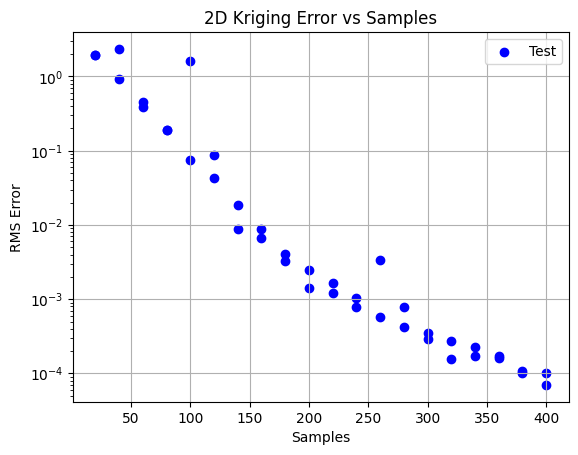

In [3]:
points_2d = []
model_error_2d = []
training_time_2d = []
evaluation_time_2d = []
points_2d, model_error_2d, evaluation_time_2d, training_time_2d = kriging_helpers.generate_kriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=20,
    sample_high=401,
    step_size=20,
    seeds=2,
    points=points_2d,
    model_error=model_error_2d,
    training_time=training_time_2d,
    evaluation_time=evaluation_time_2d,
    output_file="kriging_model_comparison_2d.csv",
)
ax = kriging_helpers.plot_error_measure(points_2d, model_error_2d, "2D Kriging Error vs Samples")
kriging_helpers.save_plot(ax, "2D_sweep_kriging")
plt.show()


### 4-Dimensional Dataset

In [4]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kriging_helpers.create_test_points(my_function, n=1000)


Run 4D :: seed 0 :: points 20 :: error 98.66029281954229 :: train_time 0.6968914999742992 


Run 4D :: seed 0 :: points 40 :: error 37.99734307165774 :: train_time 1.7097421000362374 


Run 4D :: seed 0 :: points 60 :: error 5.0047761370044554 :: train_time 27.466434100002516 


Run 4D :: seed 0 :: points 80 :: error 2.9651857743728827 :: train_time 15.104735300003085 


Run 4D :: seed 0 :: points 100 :: error 2.287030800929469 :: train_time 33.026336000009906 


Run 4D :: seed 0 :: points 120 :: error 1.990530583179135 :: train_time 22.020972800033633 


... (20 outputs left out)

Run 4D :: seed 1 :: points 240 :: error 1.1463288784551304 :: train_time 57.18645649997052 


Run 4D :: seed 1 :: points 260 :: error 0.6379346112506603 :: train_time 99.16747439996107 


Run 4D :: seed 1 :: points 280 :: error 0.47847472113647993 :: train_time 94.2673810000415 


Run 4D :: seed 1 :: points 300 :: error 0.533133625815036 :: train_time 137.1770063000149 


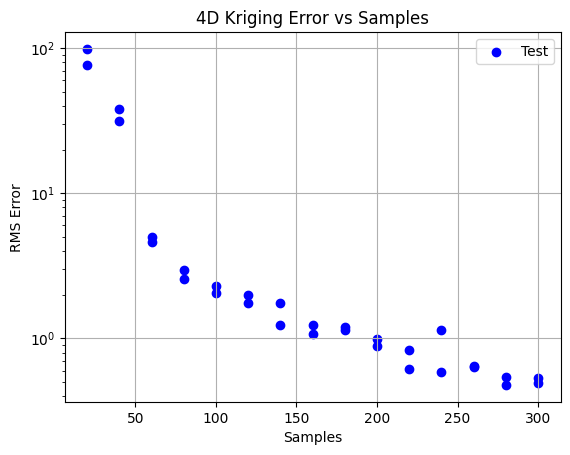

In [5]:
points_4d = []
model_error_4d = []
training_time_4d = []
evaluation_time_4d = []
points_4d, model_error_4d, evaluation_time_4d, training_time_4d = kriging_helpers.generate_kriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=20,
    sample_high=301,
    step_size=20,
    seeds=2,
    points=points_4d,
    model_error=model_error_4d,
    training_time=training_time_4d,
    evaluation_time=evaluation_time_4d,
    output_file="kriging_model_comparison_4d.csv",
)
ax = kriging_helpers.plot_error_measure(points_4d, model_error_4d, "4D Kriging Error vs Samples")
kriging_helpers.save_plot(ax, "4D_sweep_kriging")
plt.show()


### 6-Dimensional Dataset

In [6]:
key = "6D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kriging_helpers.create_test_points(my_function, n=1000)


Run 6D :: seed 0 :: points 50 :: error 1.4065553897315834 :: train_time 8.048204999999143 


Run 6D :: seed 0 :: points 100 :: error 1.3474272932702938 :: train_time 21.34982870001113 


Run 6D :: seed 0 :: points 150 :: error 1.18065159480953 :: train_time 28.734959800029173 


Run 6D :: seed 0 :: points 200 :: error 0.9360802107964266 :: train_time 45.02365589997498 


Run 6D :: seed 0 :: points 250 :: error 0.8882742480779313 :: train_time 69.53227059997153 


Run 6D :: seed 0 :: points 300 :: error 0.9159218802688714 :: train_time 73.49989009997807 


... (10 outputs left out)

Run 6D :: seed 1 :: points 350 :: error 0.8551650938716019 :: train_time 94.04157559998566 


Run 6D :: seed 1 :: points 400 :: error 0.7701006144511768 :: train_time 97.5359521000064 


Run 6D :: seed 1 :: points 450 :: error 0.7130183225804597 :: train_time 155.7488577000331 


Run 6D :: seed 1 :: points 500 :: error 0.6874328849962436 :: train_time 125.66081059997668 


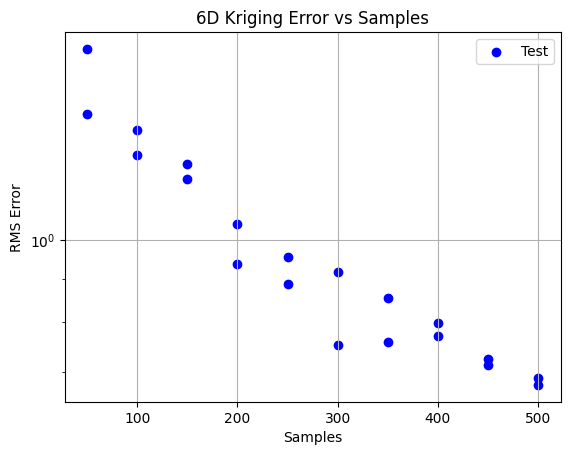

In [7]:
points_6d = []
model_error_6d = []
training_time_6d = []
evaluation_time_6d = []
points_6d, model_error_6d, evaluation_time_6d, training_time_6d = kriging_helpers.generate_kriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=501,
    step_size=50,
    seeds=2,
    points=points_6d,
    model_error=model_error_6d,
    training_time=training_time_6d,
    evaluation_time=evaluation_time_6d,
    output_file="kriging_model_comparison_6d.csv",
)
ax = kriging_helpers.plot_error_measure(points_6d, model_error_6d, "6D Kriging Error vs Samples")
kriging_helpers.save_plot(ax, "6D_sweep_kriging")
plt.show()


### 8-Dimensional Dataset

In [8]:
key = "8D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kriging_helpers.create_test_points(my_function, n=1000)


Run 8D :: seed 0 :: points 50 :: error 1.6275710377740373 :: train_time 16.764144899963867 


Run 8D :: seed 0 :: points 75 :: error 1.1231695605264853 :: train_time 33.54245259996969 


Run 8D :: seed 0 :: points 100 :: error 0.876275141556287 :: train_time 114.35802079999121 


Run 8D :: seed 0 :: points 125 :: error 0.4884138256199014 :: train_time 67.78529760002857 


Run 8D :: seed 0 :: points 150 :: error 0.3092062307238893 :: train_time 89.05711430002702 


Run 8D :: seed 0 :: points 175 :: error 0.2349572842657266 :: train_time 117.94776569999522 


... (12 outputs left out)

Run 8D :: seed 1 :: points 225 :: error 0.7335925066604899 :: train_time 436.0204841000377 


Run 8D :: seed 1 :: points 250 :: error 0.11958464113955951 :: train_time 193.75529390003067 


Run 8D :: seed 1 :: points 275 :: error 0.612469393179201 :: train_time 102.54279390000738 


Run 8D :: seed 1 :: points 300 :: error 0.6362739454524521 :: train_time 547.0923079999629 


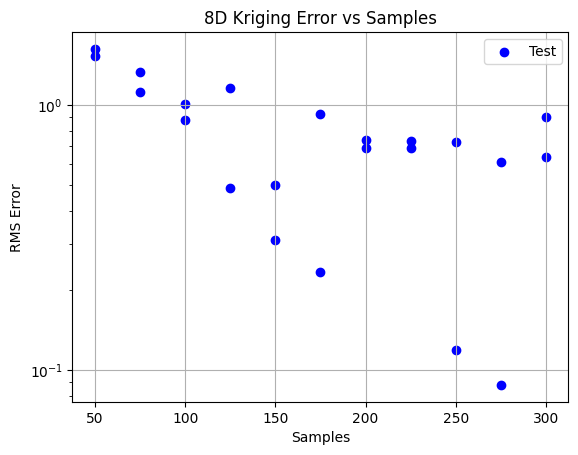

In [9]:
points_8d = []
model_error_8d = []
training_time_8d = []
evaluation_time_8d = []
points_8d, model_error_8d, evaluation_time_8d, training_time_8d = kriging_helpers.generate_kriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=301,
    step_size=25,
    seeds=2,
    points=points_8d,
    model_error=model_error_8d,
    training_time=training_time_8d,
    evaluation_time=evaluation_time_8d,
    output_file="kriging_model_comparison_8d.csv",
)
ax = kriging_helpers.plot_error_measure(points_8d, model_error_8d, "8D Kriging Error vs Samples")
kriging_helpers.save_plot(ax, "8D_sweep_kriging")
plt.show()


### 10-Dimensional Dataset

In [10]:
key = "10D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kriging_helpers.create_test_points(my_function, n=1000)


Run 10D :: seed 0 :: points 50 :: error 3.051748590181792 :: train_time 14.181139699998312 


Run 10D :: seed 0 :: points 75 :: error 1.315203611699539 :: train_time 28.561908499978017 


Run 10D :: seed 0 :: points 100 :: error 0.7761896123697237 :: train_time 30.018189700029325 


Run 10D :: seed 0 :: points 125 :: error 0.6188635756356197 :: train_time 149.29777860001195 


Run 10D :: seed 0 :: points 150 :: error 0.43205767509838233 :: train_time 116.45238370000152 


Run 10D :: seed 0 :: points 175 :: error 0.3448802154485221 :: train_time 146.6663944000029 


... (20 outputs left out)

Run 10D :: seed 1 :: points 325 :: error 0.14005322345061486 :: train_time 656.3299347999855 


Run 10D :: seed 1 :: points 350 :: error 0.12720791465837708 :: train_time 269.6665030000149 


Run 10D :: seed 1 :: points 375 :: error 0.7226813370857568 :: train_time 17.15868940000655 


Run 10D :: seed 1 :: points 400 :: error 0.10994528208333094 :: train_time 249.0653677000082 


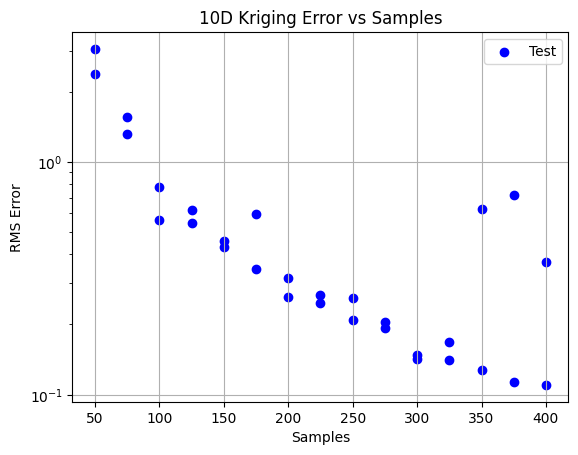

In [11]:
points_10d = []
model_error_10d = []
training_time_10d = []
evaluation_time_10d = []
points_10d, model_error_10d, evaluation_time_10d, training_time_10d = kriging_helpers.generate_kriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=401,
    step_size=25,
    seeds=2,
    points=points_10d,
    model_error=model_error_10d,
    training_time=training_time_10d,
    evaluation_time=evaluation_time_10d,
    output_file="kriging_model_comparison_10d.csv",
)
ax = kriging_helpers.plot_error_measure(points_10d, model_error_10d, "10D Kriging Error vs Samples")
kriging_helpers.save_plot(ax, "10D_sweep_kriging")
plt.show()
